## `EDA.ipynb: Step 0 of the pipeline`

**Role**: First exploration of the datasets.

**Input**: `io/Health_and_Personal_Care.jsonl`, `io/meta_Health_and_Personal_Care.jsonl`.

**Output**: No output files created.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from collections import Counter
import missingno as msno
from langdetect import detect, LangDetectException, DetectorFactory

DetectorFactory.seed = 42

sns.set_theme(style="whitegrid", context="notebook")
sns.set_palette("Blues_d")

In [2]:
HERE = os.path.dirname(os.path.abspath(''))
SRC_DIR = os.path.join(HERE, "src")
IO_DIR = os.path.join(SRC_DIR, "io")

REVIEWS_PATH = os.path.join(IO_DIR, "Health_and_Personal_Care.jsonl")
META_PATH = os.path.join(IO_DIR, "meta_Health_and_Personal_Care.jsonl")

In [3]:
df_reviews = pd.read_json(REVIEWS_PATH, lines=True)
df_meta = pd.read_json(META_PATH, lines=True)

print("Reviews shape:", df_reviews.shape)
print("Meta shape:   ", df_meta.shape)

Reviews shape: (494121, 10)
Meta shape:    (60293, 14)


## 1. Raw data overview

In [4]:
df_reviews.info()
df_reviews.head()

<class 'pandas.DataFrame'>
RangeIndex: 494121 entries, 0 to 494120
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   rating             494121 non-null  int64         
 1   title              494121 non-null  str           
 2   text               494121 non-null  str           
 3   images             494121 non-null  object        
 4   asin               494121 non-null  str           
 5   parent_asin        494121 non-null  str           
 6   user_id            494121 non-null  str           
 7   timestamp          494121 non-null  datetime64[ms]
 8   helpful_vote       494121 non-null  int64         
 9   verified_purchase  494121 non-null  bool          
dtypes: bool(1), datetime64[ms](1), int64(2), object(1), str(5)
memory usage: 156.5+ MB


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,4,12 mg is 12 on the periodic table people! Mg f...,This review is more to clarify someone else’s ...,[],B07TDSJZMR,B07TDSJZMR,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,2020-02-06 00:49:35.902,3,True
1,5,Save the lanet using less plastic.,Love these easy multitasking bleach tablets. B...,[],B08637FWWF,B08637FWWF,AEVWAM3YWN5URJVJIZZ6XPD2MKIA,2020-11-02 22:03:06.880,3,True
2,5,Fantastic,I have been suffering a couple months with hee...,[],B07KJVGNN5,B07KJVGNN5,AHSPLDNW5OOUK2PLH7GXLACFBZNQ,2019-07-24 11:13:58.905,0,True
3,4,It holds the water and makes bubbles. That's ...,"It's cheap and it does what I wanted. The ""ma...",[],B007HY7GC2,B092RP73CX,AEZGPLOYTSAPR3DHZKKXEFPAXUAA,2022-09-04 02:29:02.725,7,True
4,1,Not for me,Didn't do a thing for me. Not saying they don'...,[],B08KYJLF5T,B08KYJLF5T,AEQAYV7RXZEBXMQIQPL6KCT2CFWQ,2022-01-20 23:53:07.262,0,True


In [5]:
df_meta.info()
df_meta.head()

<class 'pandas.DataFrame'>
RangeIndex: 60293 entries, 0 to 60292
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   main_category    60293 non-null  str    
 1   title            60293 non-null  str    
 2   average_rating   60293 non-null  float64
 3   rating_number    60293 non-null  int64  
 4   features         60293 non-null  object 
 5   description      60293 non-null  object 
 6   price            10536 non-null  float64
 7   images           60293 non-null  object 
 8   videos           60293 non-null  object 
 9   store            57947 non-null  str    
 10  categories       60293 non-null  object 
 11  details          60293 non-null  object 
 12  parent_asin      60293 non-null  str    
 13  bought_together  0 non-null      float64
dtypes: float64(3), int64(1), object(6), str(4)
memory usage: 14.8+ MB


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
0,Health & Personal Care,Silicone Bath Body Brush Exfoliator Shower Bac...,3.9,7,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Rzoeox,[],{'Package Dimensions': '15 x 3.3 x 1.5 inches;...,B07V346GZH,NaN
1,Health & Personal Care,"iPhone 7 Plus 8 Plus Screen Protector, ZHXIN T...",3.8,2,[Tough and Robust: Like all 78X screen protect...,[Features: 2.5D Arc Edge Treatment: The edge i...,NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],ZHXIN,[],"{'Brand': 'ZHXIN', 'Compatible Devices': 'Cell...",B075W927RH,NaN
2,Health & Personal Care,Zig Zag Rolling Machine 70mm Size With FREE BO...,3.9,7,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],NaN,[],{'Package Dimensions': '4.1 x 1.8 x 0.3 inches...,B01FB26VKY,NaN
3,Health & Personal Care,Sting-Kill Disposable Wipes 8 Each ( Pack of 5),4.1,6,[],"[effective on stings and bites from bees, wasp...",21.37,[{'thumb': 'https://m.media-amazon.com/images/...,[],Sting-kill,[],"{'Brand': 'Sting-kill', 'Item Form': 'Wipe', '...",B01IAI29RU,NaN
4,Health & Personal Care,Heated Eyelash Curler Mini Portable Electric E...,3.3,8,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],BiBOSS,[],{'Package Dimensions': '6.1 x 3.1 x 1.9 inches...,B08CMN38RC,NaN


In [6]:
display(df_meta["features"].to_frame())

,features
0,[]
1,[Tough and Robust: Like all 78X screen protect...
2,[]
3,[]
4,[]
...,...
60288,[]
60289,[]
60290,"[Acrylic, We don't know when or if this item w..."
60291,[]


## 2. Missing values

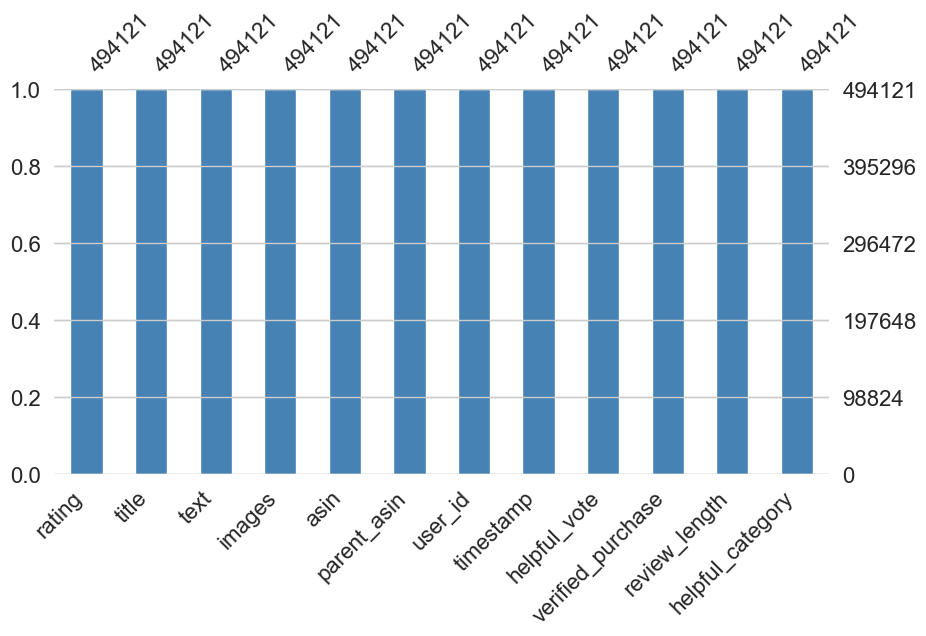

In [48]:
fig = msno.bar(df_reviews, figsize=(10, 5), color="steelblue")

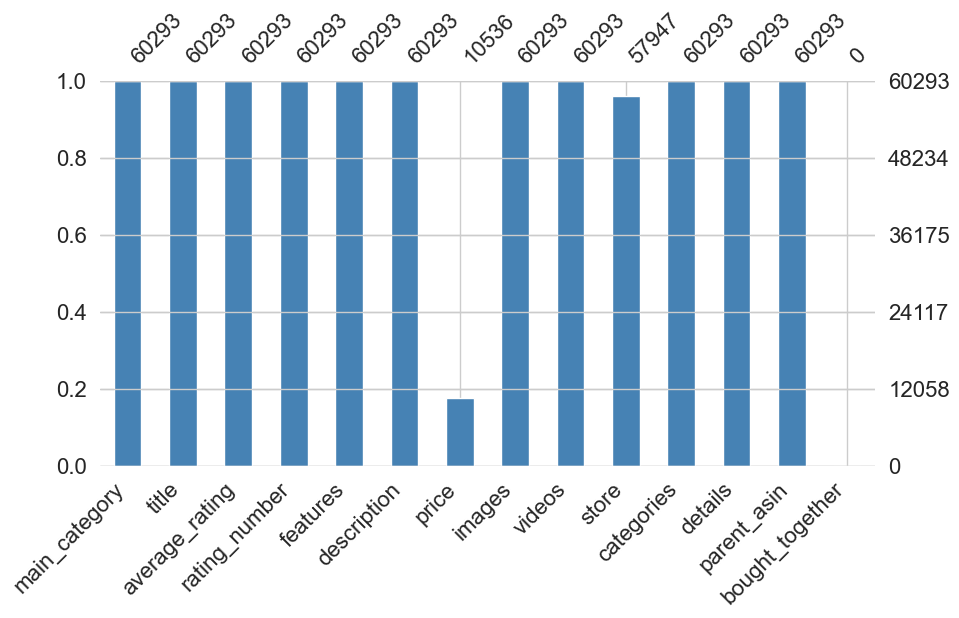

In [47]:
fig = msno.bar(df_meta, figsize=(10, 5), color="steelblue")
plt.savefig(os.path.join(IO_DIR, "missing_values_meta.png"), bbox_inches="tight")

In [9]:
print("Reviews: missing values (%):")
display(df_reviews.isnull().mean().sort_values(ascending=False).mul(100).to_frame("missing_%"))

print("\nMeta: missing values (%):")
display(df_meta.isnull().mean().sort_values(ascending=False).mul(100).to_frame("missing_%"))

Reviews: missing values (%):


,missing_%
rating,0.0
title,0.0
text,0.0
images,0.0
asin,0.0
parent_asin,0.0
user_id,0.0
timestamp,0.0
helpful_vote,0.0
verified_purchase,0.0



Meta: missing values (%):


,missing_%
bought_together,100.000000
price,82.525335
store,3.890999
average_rating,0.000000
main_category,0.000000
title,0.000000
description,0.000000
features,0.000000
rating_number,0.000000
images,0.000000


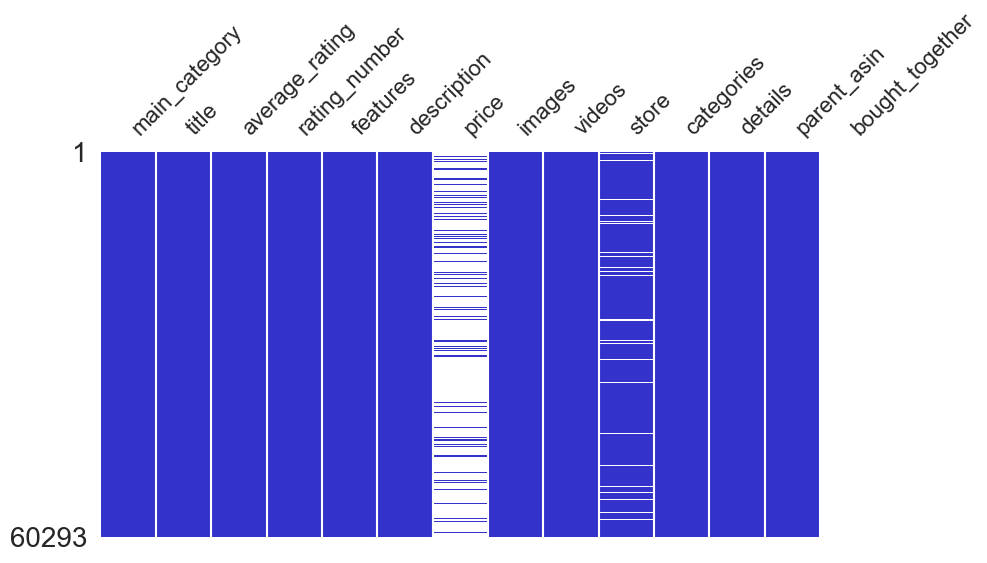

In [54]:
fig = msno.matrix(df_meta, figsize=(10, 5), color=(0.2, 0.2, 0.8), sparkline=False)

**Key findings:** `price` is missing for 82.5% of meta entries and `bought_together` is
entirely null. Downstream, price-based filtering is therefore limited to the ~17% of products
that carry a price, and `bought_together` is dropped entirely during preprocessing.

## 3. Rating distribution

*The following analyses operate on the **reviews** dataset (`Health_and_Personal_Care.jsonl`). This block covers rating distribution, review length, verified purchases, and helpful votes.*

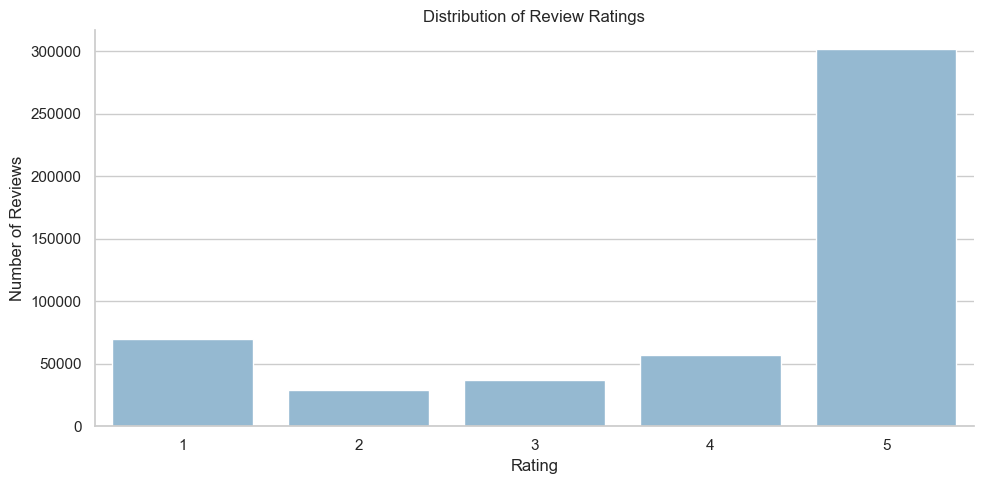

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(x="rating", data=df_reviews, ax=ax)
ax.set_title("Distribution of Review Ratings")
ax.set_xlabel("Rating")
ax.set_ylabel("Number of Reviews")
sns.despine()
plt.tight_layout()
plt.savefig(os.path.join(IO_DIR, "rating_distribution.png"))

The distribution is heavily concentrated at 5 stars (~61% of all reviews), with 1-star reviews that represents the second-largest group.                        
This means raw star ratings alone are a poor proxy for sentiment nuance: a 3-star review is rare and may carry different meaning than in a balanced distribution. **This motivates using a neural sentiment model rather than binning on star ratings directly.**

## 4. Review length analysis

In [12]:
df_reviews["review_length"] = df_reviews["text"].astype(str).str.len()

print("Review length summary statistics:")
print(df_reviews["review_length"].describe())

Review length summary statistics:
count    494121.000000
mean        188.232364
std         284.930820
min           0.000000
25%          45.000000
50%         107.000000
75%         225.000000
max       19956.000000
Name: review_length, dtype: float64


In [13]:
Q1 = df_reviews["review_length"].quantile(0.25)
Q3 = df_reviews["review_length"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_reviews[
    (df_reviews["review_length"] < lower_bound) |
    (df_reviews["review_length"] > upper_bound)
]
print(f"IQR outliers (review length): {len(outliers):,}  ",
      f"({len(outliers)/len(df_reviews)*100:.1f}% of reviews)")

IQR outliers (review length): 37,969   (7.7% of reviews)


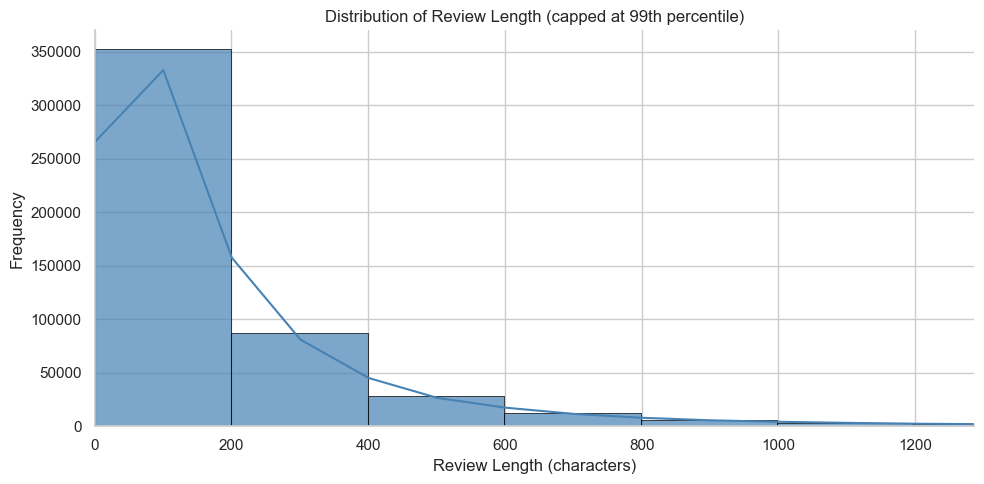

In [14]:
cap = df_reviews["review_length"].quantile(0.99)

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    df_reviews["review_length"],
    bins=100, kde=True, color="steelblue",
    edgecolor="black", alpha=0.7, ax=ax
)
ax.set_xlim(0, cap)
ax.set_title("Distribution of Review Length (capped at 99th percentile)")
ax.set_xlabel("Review Length (characters)")
ax.set_ylabel("Frequency")
sns.despine()
plt.tight_layout()

Most reviews are short: median ~107 characters, 75th percentile ~225 characters. The right tail extends to ~20,000 characters.                              
The **2,000-character cap** applied in `summarization.py` retains the vast majority of review content while protecting against edge-case inputs that would overflow the BART context window.

## 5. Verified purchase analysis

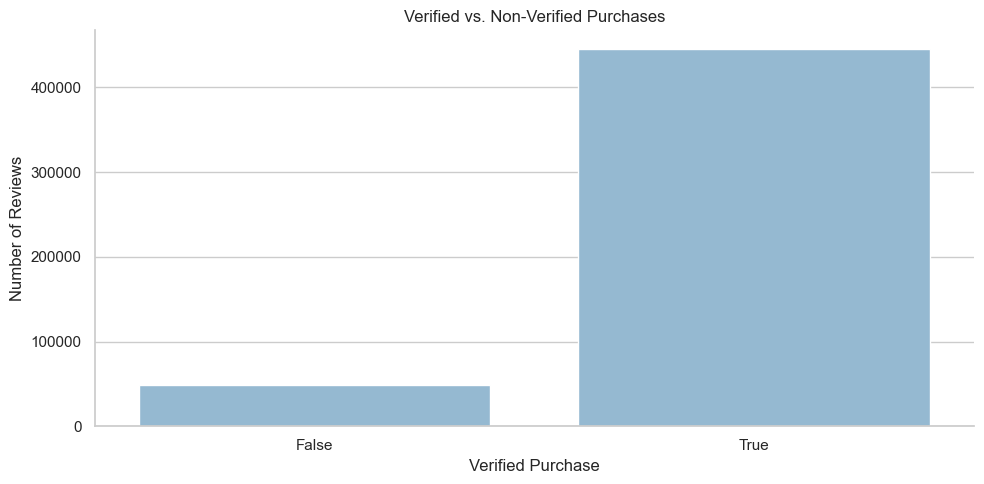

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(x="verified_purchase", data=df_reviews, ax=ax)
ax.set_title("Verified vs. Non-Verified Purchases")
ax.set_xlabel("Verified Purchase")
ax.set_ylabel("Number of Reviews")
sns.despine()
plt.tight_layout()

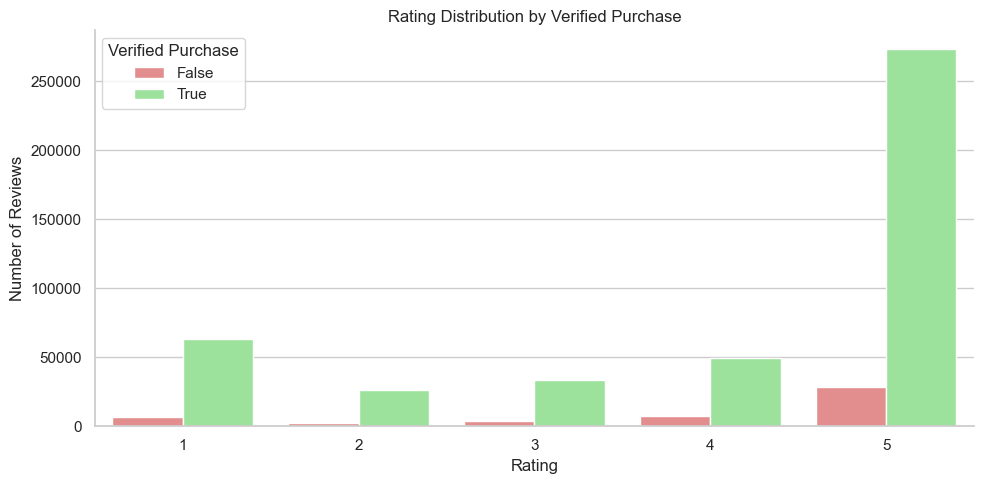

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(x="rating", hue="verified_purchase", data=df_reviews, palette={True: "lightgreen", False: "lightcoral"}, ax=ax)
ax.set_title("Rating Distribution by Verified Purchase")
ax.set_xlabel("Rating")
ax.set_ylabel("Number of Reviews")
ax.legend(title="Verified Purchase")
sns.despine()
plt.tight_layout()

~90% of reviews are verified purchases. Both verified and non-verified groups exhibit the same J-shaped rating pattern, so verified status does not introduce a distinct rating bias that would need to be controlled for in downstream modelling.

## 6. Helpful votes analysis

Descriptive statistics: helpful_vote:


,helpful_vote
count,494121.000000
mean,1.131802
std,15.437500
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,7326.000000


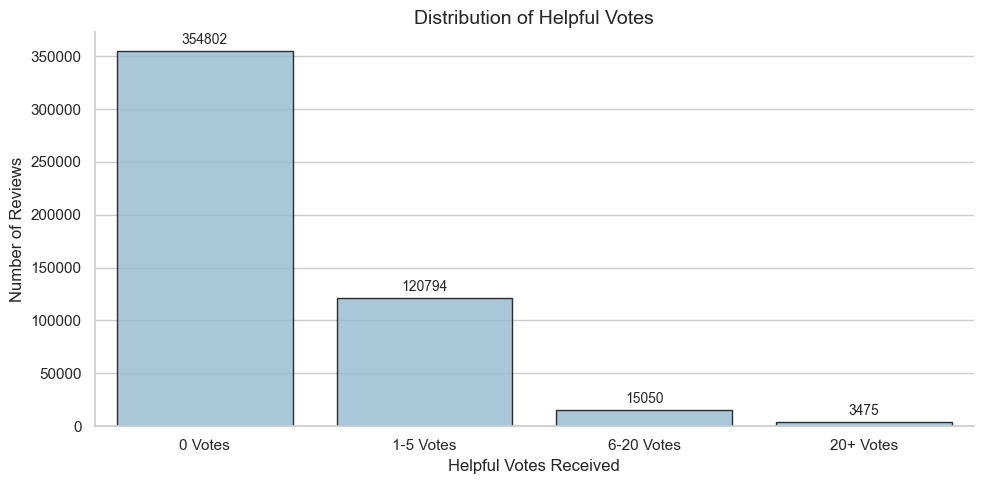

In [45]:
print("Descriptive statistics: helpful_vote:")
display(df_reviews["helpful_vote"].describe().to_frame())

def categorize_helpful_votes(votes):
    if votes == 0:
        return "0 Votes"
    elif 1 <= votes <= 5:
        return "1-5 Votes"
    elif 6 <= votes <= 20:
        return "6-20 Votes"
    else:
        return "20+ Votes"

df_reviews["helpful_category"] = df_reviews["helpful_vote"].apply(categorize_helpful_votes)
category_order = ["0 Votes", "1-5 Votes", "6-20 Votes", "20+ Votes"]

fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(
    x="helpful_category", data=df_reviews,
    order=category_order, edgecolor="black", alpha=0.8, ax=ax
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)
ax.set_title("Distribution of Helpful Votes", fontsize=14)
ax.set_xlabel("Helpful Votes Received")
ax.set_ylabel("Number of Reviews")
sns.despine()
plt.tight_layout()
plt.savefig(os.path.join(IO_DIR, "helpful_votes_distribution.png"))

The overwhelming majority of reviews receive **zero helpful votes**. This means helpful_vote cannot be used as a quality filter on its own: most reviews would be discarded. Instead, in `insights.py` reviews are **sorted descending by helpful_vote** so that the few community-validated reviews surface first when selecting representative samples per product.

## 7. Product price distribution

*The following analyses operate on the **metadata** dataset (`meta_Health_and_Personal_Care.jsonl`). This block covers product prices, top brands, and average product ratings.*

In [18]:
print("Price summary statistics:")
display(df_meta["price"].describe().to_frame())

missing_price = df_meta["price"].isna().mean() * 100
print(f"\nMissing prices: {missing_price:.1f}%")

Price summary statistics:


,price
count,10536.000000
mean,43.736799
std,168.444240
min,0.100000
25%,11.990000
50%,19.990000
75%,36.090000
max,4449.000000



Missing prices: 82.5%


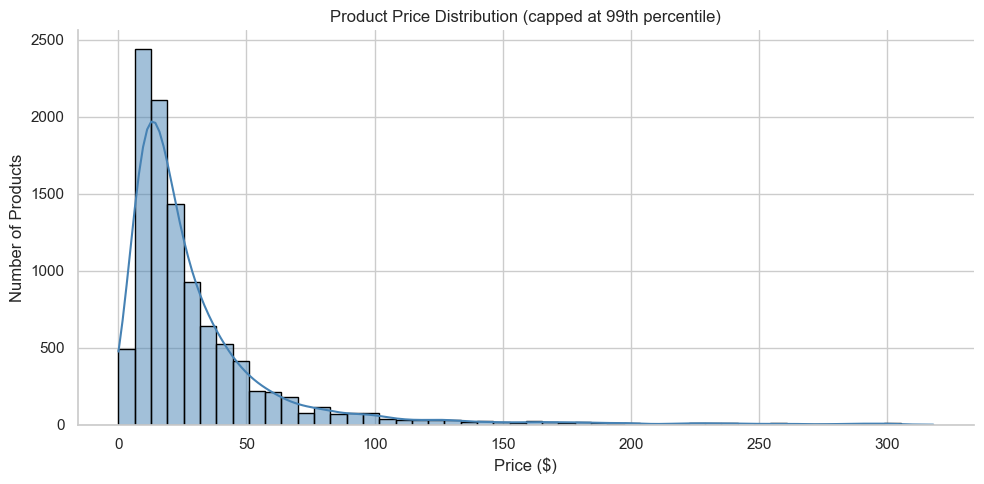

In [19]:
price_cap = df_meta["price"].dropna().quantile(0.99)
price_plot = df_meta["price"].dropna()
price_plot = price_plot[price_plot < price_cap]

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(price_plot, bins=50, color="steelblue", edgecolor="black", kde=True, ax=ax)
ax.set_title("Product Price Distribution (capped at 99th percentile)")
ax.set_xlabel("Price ($)")
ax.set_ylabel("Number of Products")
sns.despine()
plt.tight_layout()

82.5% of products have no price. The available prices are right-skewed (median ~$20, max ~$4,449). Because price is missing for most products, **any price-based filtering would silently discard the majority of the catalogue**: this is a documented limitation of the pipeline.

## 8. Top brands

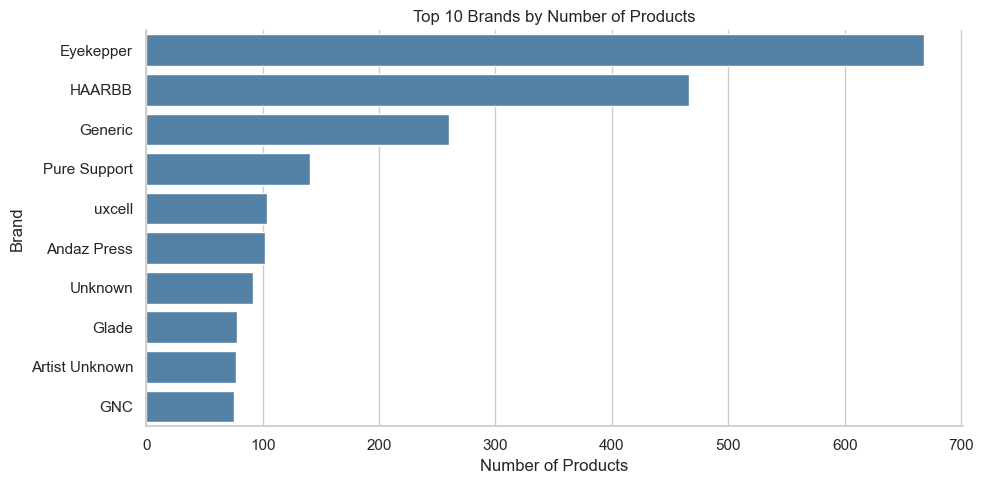

In [20]:
top_brands = df_meta["store"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_brands.values, y=top_brands.index, color="steelblue", ax=ax)
ax.set_title("Top 10 Brands by Number of Products")
ax.set_xlabel("Number of Products")
ax.set_ylabel("Brand")
sns.despine()
plt.tight_layout()

The brand landscape is fragmented: no single store dominates the catalogue, which is consistent with a marketplace model where many small sellers coexist alongside a few large brands. Brand concentration is low enough that store identity is not a reliable signal for product quality in isolation.


## 9. Average rating distribution (products)

In [21]:
print("Product average_rating summary:")
display(df_meta["average_rating"].describe().to_frame())

Product average_rating summary:


,average_rating
count,60293.000000
mean,3.979625
std,0.846449
min,1.000000
25%,3.500000
50%,4.100000
75%,4.600000
max,5.000000


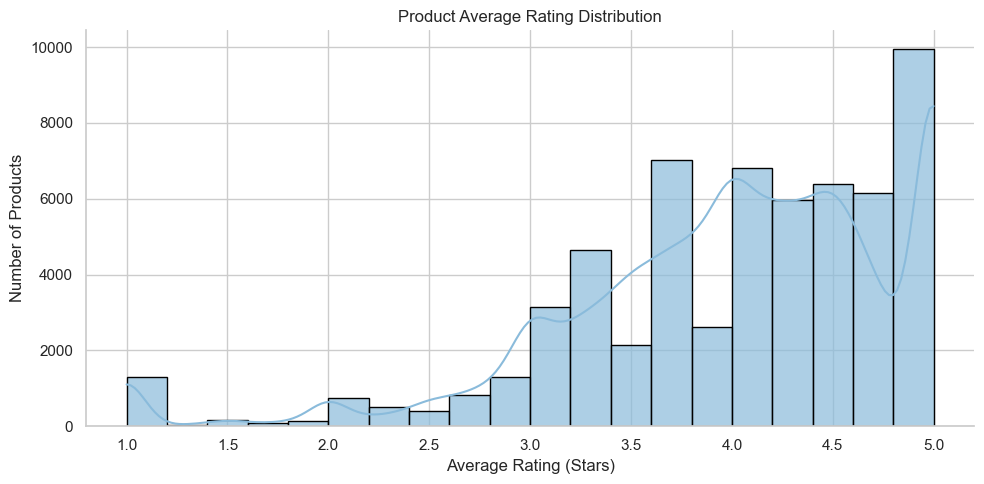

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df_meta, x="average_rating", bins=20, kde=True,
             edgecolor="black", alpha=0.7, ax=ax)
ax.set_title("Product Average Rating Distribution")
ax.set_xlabel("Average Rating (Stars)")
ax.set_ylabel("Number of Products")
sns.despine()
plt.tight_layout()

Product-level average ratings are heavily concentrated above 4 stars, with a spike at 5.0. This mirrors the positivity bias seen at the individual review level and confirms that the bias is structural across products, not just a property of individual reviewers.

## 10. Merged dataset analysis

> The following analyses operate on the merged dataset. The merge and deduplication steps here mirror `preprocessing.py` for analysis purposes only: they are not the pipeline execution.

In [23]:
df = df_reviews.merge(df_meta, on="parent_asin", how="left")
print("Merged shape:", df.shape)
display(df.head())

Merged shape: (494121, 25)


,rating,title_x,text,images_x,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,...,rating_number,features,description,price,images_y,videos,store,categories,details,bought_together
0,4,12 mg is 12 on the periodic table people! Mg f...,This review is more to clarify someone else’s ...,[],B07TDSJZMR,B07TDSJZMR,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,2020-02-06 00:49:35.902,3,True,...,470,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Life Nutrition,[],"{'Brand': 'Life Nutrition', 'Unit Count': '60 ...",NaN
1,5,Save the lanet using less plastic.,Love these easy multitasking bleach tablets. B...,[],B08637FWWF,B08637FWWF,AEVWAM3YWN5URJVJIZZ6XPD2MKIA,2020-11-02 22:03:06.880,3,True,...,181,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'Great for bathroom cleaning!', 'ur...",Evolve,[],"{'Brand': 'Evolve', 'Scent': 'Fresh,Lemon', 'P...",NaN
2,5,Fantastic,I have been suffering a couple months with hee...,[],B07KJVGNN5,B07KJVGNN5,AHSPLDNW5OOUK2PLH7GXLACFBZNQ,2019-07-24 11:13:58.905,0,True,...,78,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'Very soft and comfortable, easy to...",Dr.Foot,[],"{'Is Discontinued By Manufacturer': 'No', 'Pro...",NaN
3,4,It holds the water and makes bubbles. That's ...,"It's cheap and it does what I wanted. The ""ma...",[],B007HY7GC2,B092RP73CX,AEZGPLOYTSAPR3DHZKKXEFPAXUAA,2022-09-04 02:29:02.725,7,True,...,8312,[Fizz your feet: Active bubble massage soothes...,[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'My opinion on this foot spa. ', 'u...",Homedics,[],"{'Use for': 'Feet', 'Power Source': 'Corded El...",NaN
4,1,Not for me,Didn't do a thing for me. Not saying they don'...,[],B08KYJLF5T,B08KYJLF5T,AEQAYV7RXZEBXMQIQPL6KCT2CFWQ,2022-01-20 23:53:07.262,0,True,...,94,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Nature's Nutrition,[],"{'Brand': 'Nature's Nutrition', 'Unit Count': ...",NaN


In [24]:
print("Missing values in merged dataset (%):")
display(
    df.isnull().mean().sort_values(ascending=False).mul(100)
     .to_frame("missing_%")
     .query("`missing_%` > 0")
)

Missing values in merged dataset (%):


,missing_%
bought_together,100.000000
price,65.794006
store,2.547959


In [25]:
columns_to_drop = ["images_x", "images_y", "videos", "bought_together"]
df = df.drop(columns=columns_to_drop, errors="ignore")
df["price"] = pd.to_numeric(df["price"], errors="coerce")
print("Shape after dropping unused columns:", df.shape)

Shape after dropping unused columns: (494121, 21)


In [26]:
df = df[df["text"].notnull() & (df["text"].str.len() > 0)]
print("Shape after filtering empty texts:", df.shape)

Shape after filtering empty texts: (494094, 21)


In [27]:
n_dupes = df.duplicated(subset=["user_id", "parent_asin", "timestamp"]).sum()
print(f"Duplicate reviews: {n_dupes:,}")

df = df.drop_duplicates(subset=["user_id", "parent_asin", "timestamp"])
print(f"Shape after deduplication: {df.shape}")
print(f"Remaining duplicates: {df.duplicated(subset=['user_id','parent_asin','timestamp']).sum()}")

Duplicate reviews: 5,130
Shape after deduplication: (488964, 21)
Remaining duplicates: 0


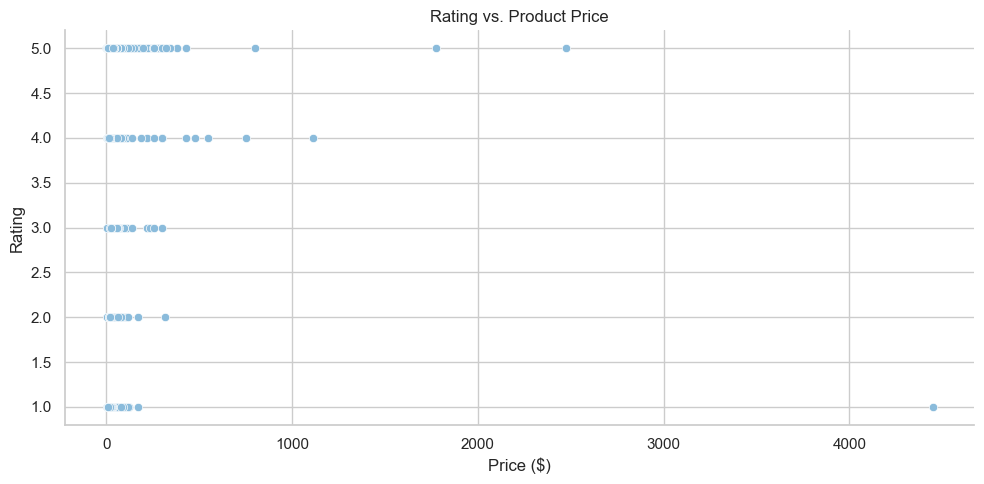

In [28]:
df_price = df.dropna(subset=["price"])

fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(x="price", y="rating", data=df_price.sample(5000), ax=ax)
ax.set_title("Rating vs. Product Price")
ax.set_xlabel("Price ($)")
ax.set_ylabel("Rating")
sns.despine()
plt.tight_layout()

No clear relationship between price and rating is visible. High-rated products exist at all price points, suggesting that price is not a reliable predictor of review sentiment in this catalogue, and given that 82% of prices are missing, this finding is also limited in scope.

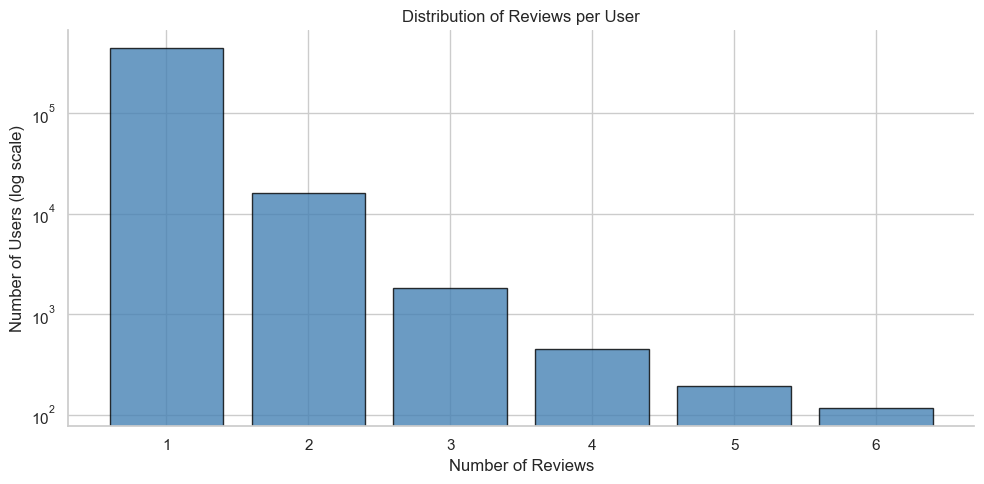

In [29]:
reviews_per_user = df.groupby("user_id").size()
cap = int(reviews_per_user.quantile(0.999))

counts = reviews_per_user[reviews_per_user <= cap].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(counts.index, counts.values, color="steelblue", edgecolor="black", alpha=0.8)
ax.set_yscale("log")
ax.set_title("Distribution of Reviews per User")
ax.set_xlabel("Number of Reviews")
ax.set_ylabel("Number of Users (log scale)")
ax.set_xticks(range(1, cap + 1))
sns.despine()
plt.tight_layout()

The dataset is dominated by one-time reviewers: the vast majority of users contributed exactly one review, with counts dropping steeply at each subsequent value. This is consistent with incidental purchasing behaviour rather than an engaged reviewer community. The implication for the pipeline is that per-user history is too sparse to support user-level personalisation, so product-level signals are the only reliable anchor.

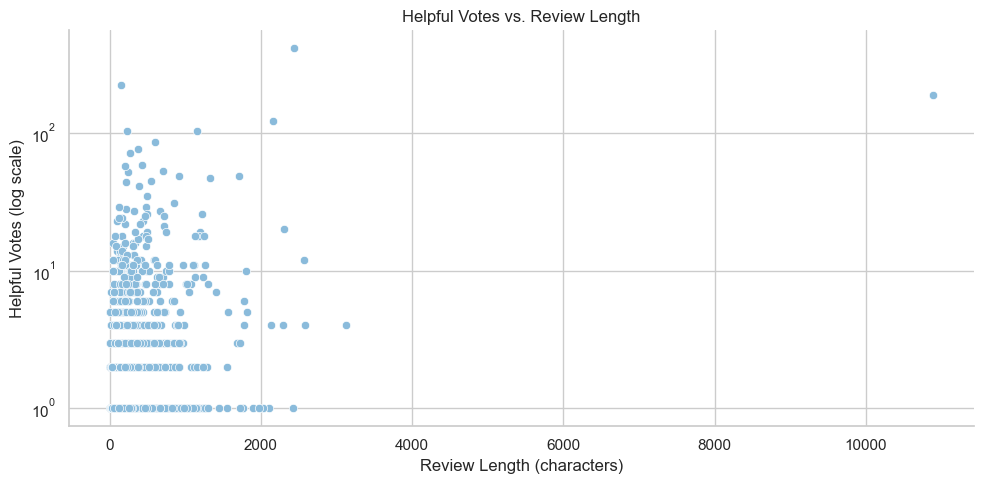

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(x="review_length", y="helpful_vote",
                data=df.sample(5000), ax=ax)
ax.set_yscale("log")
ax.set_title("Helpful Votes vs. Review Length")
ax.set_xlabel("Review Length (characters)")
ax.set_ylabel("Helpful Votes (log scale)")
sns.despine()
plt.tight_layout()

Longer reviews tend to attract slightly more helpful votes, but the relationship is weak and noisy. The overwhelming majority of reviews, regardless of length, receive zero helpful votes. This confirms that review length alone is not a proxy for community validation, reinforcing the decision to use helpful_vote directly as a ranking signal.

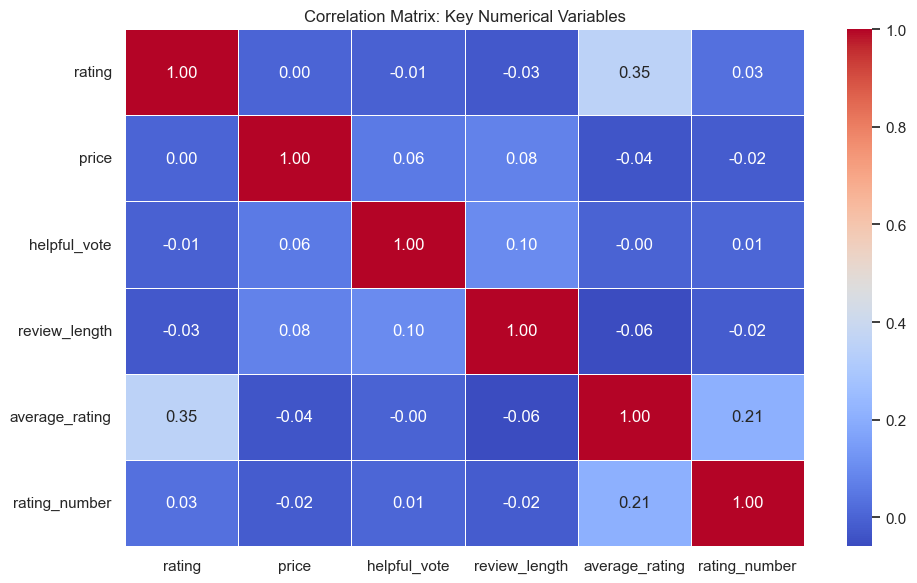

In [31]:
numeric_cols = ["rating", "price", "helpful_vote", "review_length",
                "average_rating", "rating_number"]
corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm",
            fmt=".2f", linewidths=0.5, ax=ax)
ax.set_title("Correlation Matrix: Key Numerical Variables")
plt.tight_layout()

The strongest correlation is between rating and average_rating (as one could expect). helpful_vote and review_length show a weak positive correlation. Price has near-zero correlation with everything, partly due to the high missingness rate.

## 11. Word analysis

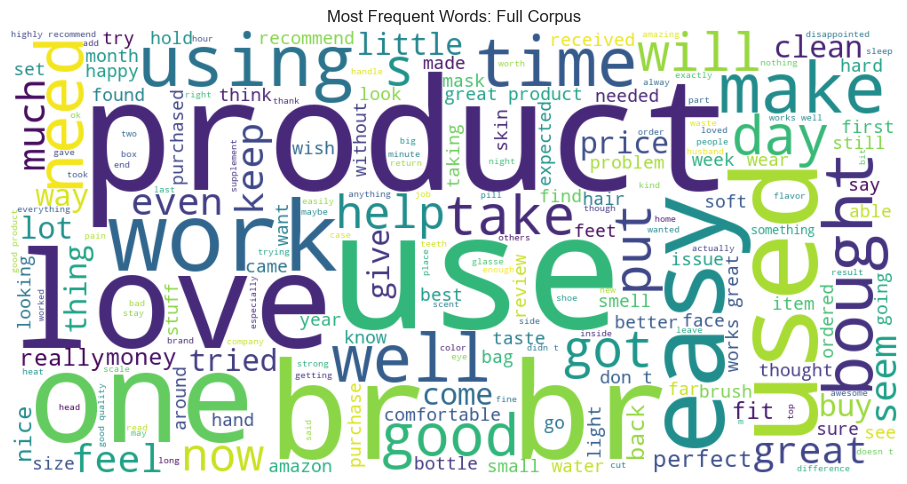

In [32]:
# Joining the full corpus is slow; wordcloud generation dominates
text_all = " ".join(df["text"].dropna().astype(str)).lower()
stopwords = set(STOPWORDS)

wc = WordCloud(width=1000, height=500, background_color="white",
               stopwords=stopwords).generate(text_all)

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(wc)
ax.axis("off")
ax.set_title("Most Frequent Words: Full Corpus")
plt.tight_layout()

Even with stopwords removed the most visible terms are product-category words (product, skin, hair, vitamin) and sentiment carriers (love, great, works, recommend). This confirms the corpus is semantically coherent and suitable for embedding-based retrieval.

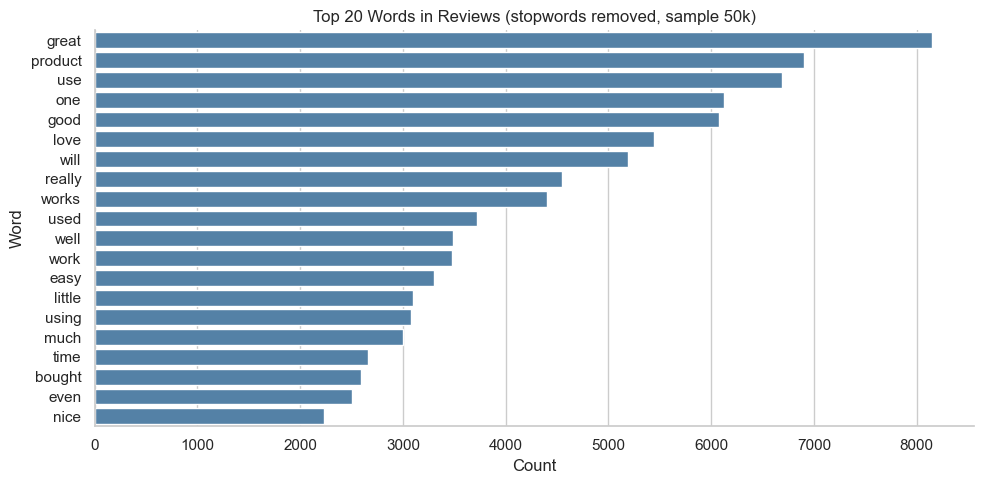

In [33]:
# Sample 50k reviews for word frequency to keep this cell fast
sample_text = df["text"].dropna().sample(50_000, random_state=42).str.lower()
words_filtered = [
    w for line in sample_text for w in line.split()
    if w not in stopwords and w.isalpha()
]
top_words = Counter(words_filtered).most_common(20)
top_words_df = pd.DataFrame(top_words, columns=["word", "count"])

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x="count", y="word", data=top_words_df, color="steelblue", ax=ax)
ax.set_title("Top 20 Words in Reviews (stopwords removed, sample 50k)")
ax.set_xlabel("Count")
ax.set_ylabel("Word")
sns.despine()
plt.tight_layout()

The most frequent content words across the corpus are generic category descriptors and positive sentiment terms. Negative sentiment words are rare in the aggregate, consistent with the positivity bias observed in the rating distribution.

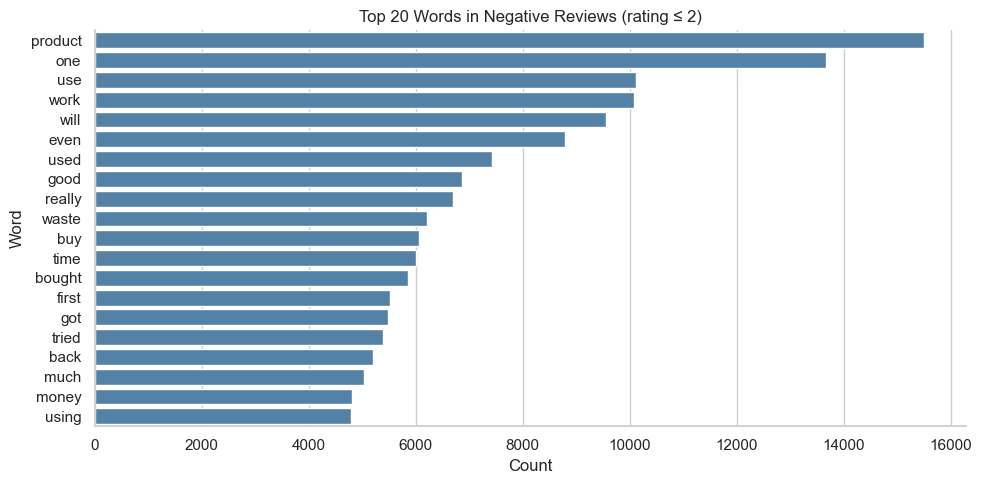

In [34]:
negative_reviews = df[df["rating"] <= 2]
text_neg = " ".join(negative_reviews["text"].dropna().astype(str)).lower()
words_neg = [w for w in text_neg.split() if w not in stopwords and w.isalpha()]
top_neg = Counter(words_neg).most_common(20)
top_neg_df = pd.DataFrame(top_neg, columns=["word", "count"])

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x="count", y="word", data=top_neg_df, color="steelblue", ax=ax)
ax.set_title("Top 20 Words in Negative Reviews (rating ≤ 2)")
ax.set_xlabel("Count")
ax.set_ylabel("Word")
sns.despine()
plt.tight_layout()

In negative reviews, category words still dominate, but quality-failure terms appear prominently. This vocabulary contrast between positive and negative reviews is the kind of signal the sentiment model is trained to pick up.

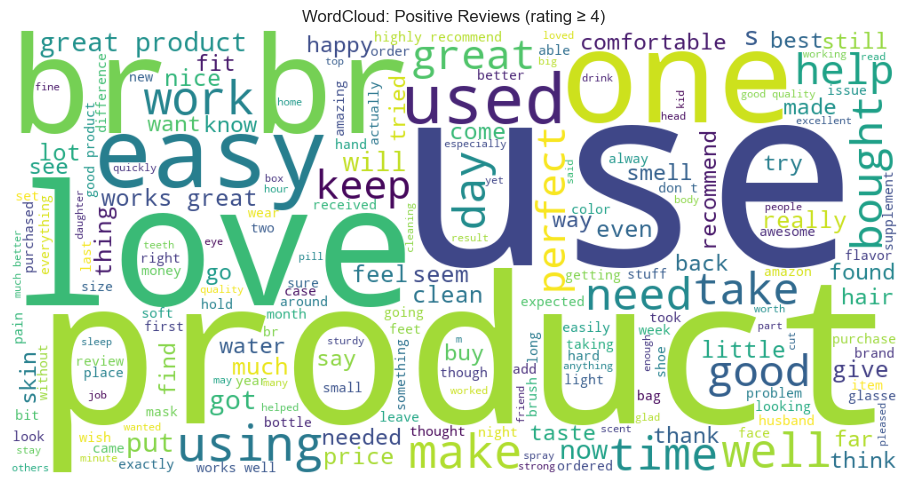

In [35]:
positive_reviews = df[df["rating"] >= 4]
text_pos = " ".join(positive_reviews["text"].dropna().astype(str)).lower()

wc_pos = WordCloud(width=1000, height=500, background_color="white",
                   stopwords=stopwords).generate(text_pos)
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(wc_pos)
ax.axis("off")
ax.set_title("WordCloud: Positive Reviews (rating ≥ 4)")
plt.tight_layout()

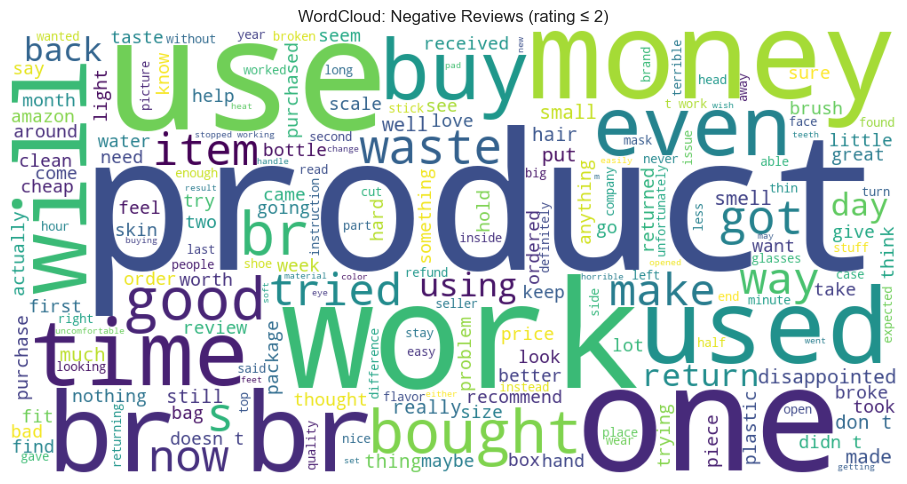

In [36]:
wc_neg = WordCloud(width=1000, height=500, background_color="white",
                   stopwords=stopwords).generate(text_neg)
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(wc_neg)
ax.axis("off")
ax.set_title("WordCloud: Negative Reviews (rating ≤ 2)")
plt.tight_layout()

## 12. Reviews per product distribution

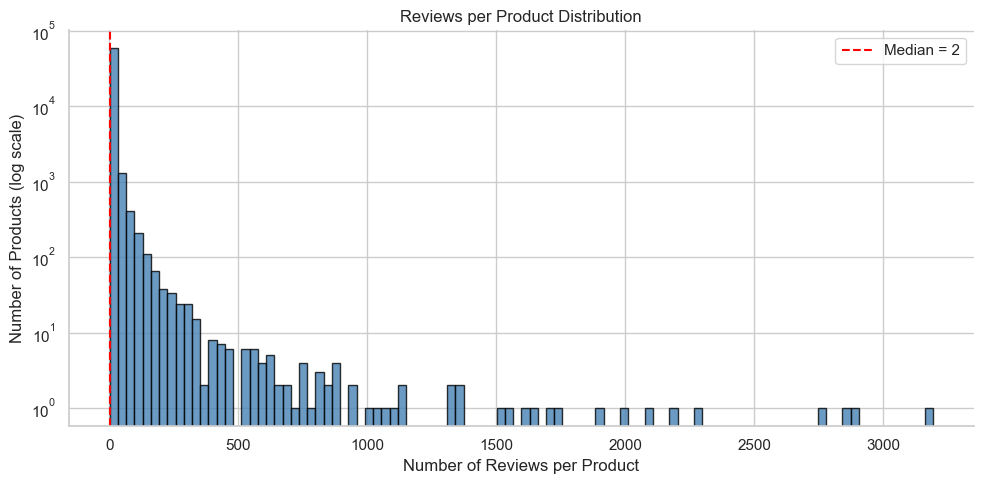

In [37]:
reviews_per_product = df_reviews.groupby("parent_asin").size()
median_reviews = reviews_per_product.median()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(reviews_per_product, bins=100, color="steelblue",
        edgecolor="black", alpha=0.8)
ax.set_yscale("log")
ax.axvline(median_reviews, color="red", linestyle="--",
           label=f"Median = {median_reviews:.0f}")
ax.set_title("Reviews per Product Distribution")
ax.set_xlabel("Number of Reviews per Product")
ax.set_ylabel("Number of Products (log scale)")
ax.legend()
sns.despine()
plt.tight_layout()
plt.savefig(os.path.join(IO_DIR, "reviews_per_product.png"))

In [38]:
thresholds = [1, 3, 5, 10, 20]
print("Review count threshold analysis:")
print(f"  Total products: {len(reviews_per_product):,}")
for t in thresholds:
    n = (reviews_per_product < t).sum()
    pct = n / len(reviews_per_product) * 100
    print(f"  Products with fewer than {t:>2} review(s): {n:>6,}  ({pct:.1f}%)")

Review count threshold analysis:
  Total products: 60,274
  Products with fewer than  1 review(s):      0  (0.0%)
  Products with fewer than  3 review(s): 34,052  (56.5%)
  Products with fewer than  5 review(s): 43,318  (71.9%)
  Products with fewer than 10 review(s): 51,540  (85.5%)
  Products with fewer than 20 review(s): 56,075  (93.0%)


The long tail means a substantial fraction of products have very few reviews. Products below the minimum review threshold (e.g. fewer than 3) will produce **thin or near-extractive summaries** in `summarization.py`, so the model has
little to synthesise. This is a documented limitation: summary quality is lower for sparse products.

## 13. Helpful vote distribution

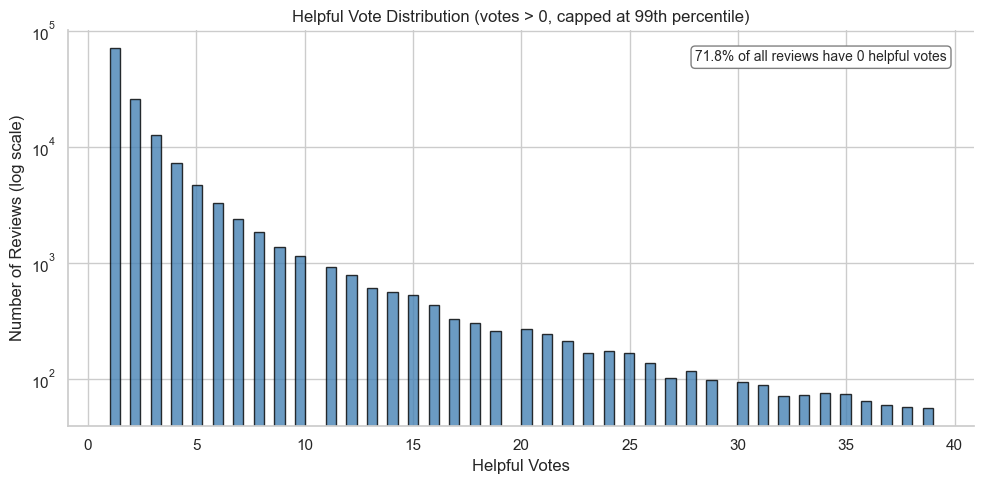

In [39]:
zero_pct = (df_reviews["helpful_vote"] == 0).mean() * 100
votes_nonzero = df_reviews.loc[df_reviews["helpful_vote"] > 0, "helpful_vote"]
cap = votes_nonzero.quantile(0.99)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(votes_nonzero[votes_nonzero <= cap], bins=80,
        color="steelblue", edgecolor="black", alpha=0.8)
ax.set_yscale("log")
ax.set_title("Helpful Vote Distribution (votes > 0, capped at 99th percentile)")
ax.set_xlabel("Helpful Votes")
ax.set_ylabel("Number of Reviews (log scale)")
ax.text(0.97, 0.95, f"{zero_pct:.1f}% of all reviews have 0 helpful votes",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))
sns.despine()
plt.tight_layout()

## 14. Language detection

A sample of reviews is checked for language to quantify non-English content in the
corpus, motivating the multilingual limitation noted in the conclusions.

In [40]:
sample = df_reviews["text"].dropna().sample(3000, random_state=42)

def safe_detect(text):
    try:
        return detect(str(text))
    except LangDetectException:
        return "unknown"

langs = sample.apply(safe_detect)
lang_counts = langs.value_counts()
lang_pct = langs.value_counts(normalize=True) * 100

print("Language distribution (sample of 3,000 reviews):")
display(
    pd.DataFrame({"Count": lang_counts, "Percentage": lang_pct.round(2)}).head(10)
)

Language distribution (sample of 3,000 reviews):


,Count,Percentage
text,,
en,2793,93.10
af,45,1.50
es,26,0.87
ro,26,0.87
ca,12,0.40
so,12,0.40
de,11,0.37
fr,11,0.37
no,7,0.23


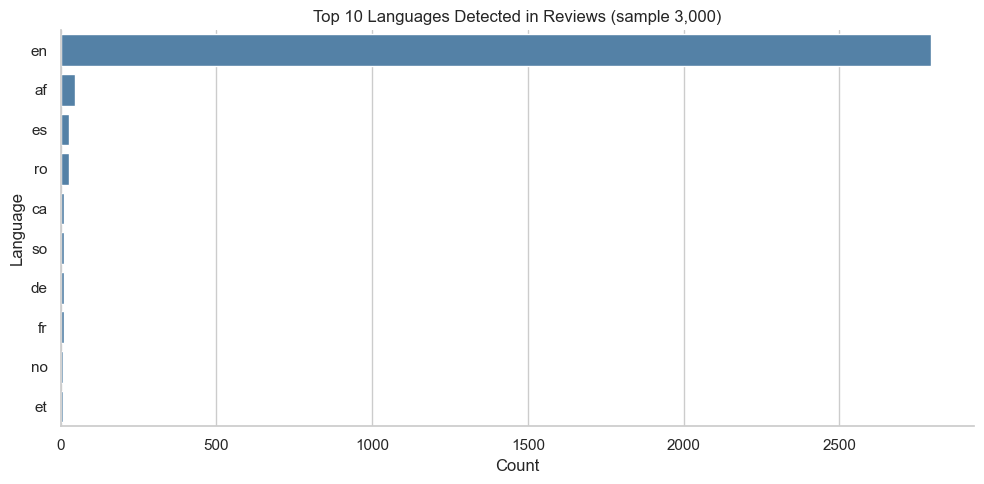

In [41]:
top_langs = lang_counts.head(10)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_langs.values, y=top_langs.index, color="steelblue", ax=ax)
ax.set_title("Top 10 Languages Detected in Reviews (sample 3,000)")
ax.set_xlabel("Count")
ax.set_ylabel("Language")
sns.despine()
plt.tight_layout()

The vast majority of reviews are English. Non-English reviews (Spanish, French, etc.) form a small but non-zero fraction of the corpus. Both **E5-base-v2** (embedding) and **BART** (summarization) are English-centric models: non-English reviews will produce lower-quality embeddings and summaries. This is a documented limitation.

## 15. K-selection analysis

We selected K=200 based on a silhouette score analysis across K ∈ {10, 20, 30, 40, 50, 75, 100, 150, 200, 250, 300}. All scores fell within 0.023–0.032, consistent with the diffuse geometry of high-dimensional transformer embedding spaces. K=200 achieved the highest silhouette score (0.0317); scores decline at K=250 and K=300, confirming K=200 as the optimum within the tested range.

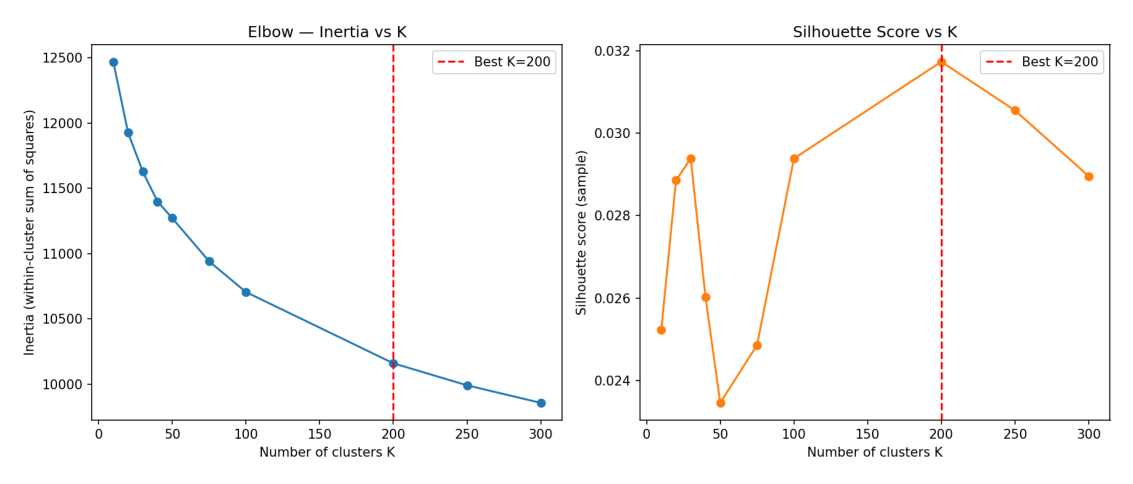

In [42]:
img = mpimg.imread(os.path.join(IO_DIR, "k_selection.png"))
fig, ax = plt.subplots(figsize=(12, 5))
ax.imshow(img)
ax.axis("off")
plt.tight_layout()

In [43]:
sweep_results = pd.DataFrame({
    "K":          [10, 20, 30, 40, 50, 75, 100, 150, 200, 250, 300],
    "Inertia":    [12470.93, 11927.83, 11628.03, 11400.07, 11272.20,
                   10941.34, 10706.09, 10402.38, 10160.35, 9991.66, 9857.22],
    "Silhouette": [0.0252, 0.0289, 0.0294, 0.0260, 0.0235,
                   0.0249, 0.0294, 0.0321, 0.0317, 0.0306, 0.0290],
})
display(sweep_results)

,K,Inertia,Silhouette
0,10,12470.93,0.0252
1,20,11927.83,0.0289
2,30,11628.03,0.0294
3,40,11400.07,0.0260
4,50,11272.20,0.0235
5,75,10941.34,0.0249
6,100,10706.09,0.0294
7,150,10402.38,0.0321
8,200,10160.35,0.0317
9,250,9991.66,0.0306
